In [1]:
from pystac_client import Client

In [2]:
catalogue = Client.open('https://earth-search.aws.element84.com/v1')

In [4]:
collection = catalogue.get_collection("sentinel-2-l2a")

In [19]:
item=collection.get_item('S2B_45RXL_20221031_0_L2A')

In [20]:
print(item.assets.keys())

dict_keys(['aot', 'blue', 'coastal', 'granule_metadata', 'green', 'nir', 'nir08', 'nir09', 'red', 'rededge1', 'rededge2', 'rededge3', 'scl', 'swir16', 'swir22', 'thumbnail', 'tileinfo_metadata', 'visual', 'wvp', 'aot-jp2', 'blue-jp2', 'coastal-jp2', 'green-jp2', 'nir-jp2', 'nir08-jp2', 'nir09-jp2', 'red-jp2', 'rededge1-jp2', 'rededge2-jp2', 'rededge3-jp2', 'scl-jp2', 'swir16-jp2', 'swir22-jp2', 'visual-jp2', 'wvp-jp2'])


In [21]:
visual_url=item.assets['visual'].href

In [22]:
print(visual_url)

https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/45/R/XL/2022/10/S2B_45RXL_20221031_0_L2A/TCI.tif


In [23]:
import rasterio

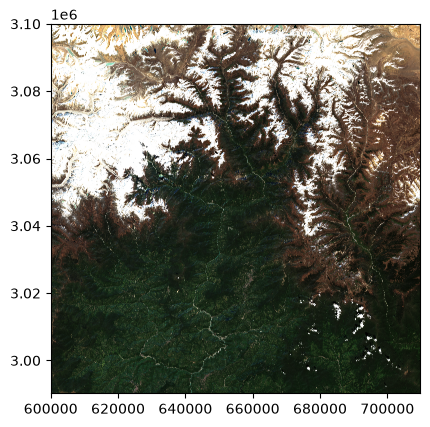

In [24]:
with rasterio.open(item.assets["visual"].href) as dataset:
    rasterio.plot.show(dataset)

In [25]:
print(dataset.crs, dataset.width, dataset.height, dataset.count, dataset.bounds)

EPSG:32645 10980 10980 3 BoundingBox(left=600000.0, bottom=2990220.0, right=709800.0, top=3100020.0)


In [26]:
from rasterio.warp import transform_bounds

In [27]:
from rasterio.windows import from_bounds

In [28]:
from rasterio.plot import show

In [29]:
bbox = [88.13, 27.86, 88.23, 27.96]

(611149.5180046826, 3082206.7273929715, 621097.9207869825, 3093380.314373674)
(3, 1117, 995)


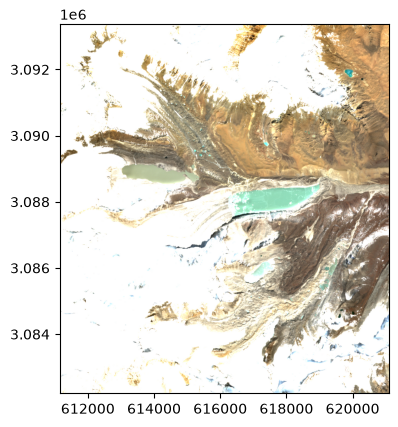

In [31]:
with rasterio.open(item.assets["visual"].href) as dataset:
    utm_bounds = transform_bounds("EPSG:4326",dataset.crs,*bbox)
    print(utm_bounds)
    window = from_bounds(*utm_bounds, transform=dataset.transform)
    lake = dataset.read(window=window)
    print(lake.shape)
    show(lake, transform=dataset.window_transform(window))